# Stage 10: Threshold optimisation and the cost-sensitive decision framework
A model outputs a probability, and the **business** decides what to do with it. This stage turns PDs into a lending
policy by putting a price on each kind of error:

| Outcome | What happens | Cost / benefit per loan |
|---|---|---|
| Approve, repays | Earn the margin | + `margin × AMT_CREDIT` |
| **Approve, defaults (false approval)** | Lose part of the exposure | − `LGD × AMT_CREDIT` |
| **Decline, would have repaid (false rejection)** | Lost customer and profit | opportunity cost `margin × AMT_CREDIT` |
| Decline, would have defaulted | Loss avoided | 0 |

**Assumptions** (config `business`): LGD = 60% (unsecured consumer credit), lifetime net margin = 15% of the credit amount.
They are *assumptions*: Section 5 shows how the optimal cutoff moves when they change.

**Theory check:** with calibrated PDs, approving is profitable while `(1 − PD) × margin > PD × LGD`, so the break-even is
`PD* = margin / (margin + LGD) = 0.15 / 0.75 = 20%`. The empirical optimum should land close to that.

The threshold is chosen on the **validation** set and then evaluated on the **test** set.

In [1]:
import sys
import warnings
from pathlib import Path

ROOT = Path.cwd().resolve().parent if Path.cwd().name == "notebooks" else Path.cwd().resolve()
if str(ROOT / "src") not in sys.path:
    sys.path.insert(0, str(ROOT / "src"))
warnings.filterwarnings("ignore")

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from credit_risk.artifacts import load_final_model, load_split_frames
from credit_risk.config import get_paths, load_config
from credit_risk.thresholds import (
    assign_decision,
    assign_grade,
    break_even_pd,
    candidate_thresholds,
    make_policy,
    plot_profit_curve,
    plot_tradeoff,
    save_policy,
    threshold_sweep,
)
from credit_risk.viz import COLORS, savefig, set_style

cfg = load_config()
paths = get_paths(cfg)
set_style()
ID, TARGET = cfg["data"]["id_column"], cfg["data"]["target"]
LGD, MARGIN = cfg["business"]["lgd"], cfg["business"]["profit_margin"]

train, valid, test = load_split_frames(paths)
model = load_final_model(paths)
pd_valid = model.predict_pd(valid)
pd_test = pd.read_parquet(paths["processed_data"] / "test_predictions.parquet").set_index(ID).loc[test[ID], "pd"].to_numpy()
print(f"Analytic break-even PD: {break_even_pd(LGD, MARGIN):.3f}")

Analytic break-even PD: 0.200


## 1. Sweep every cutoff on the validation set

In [2]:
sweep = threshold_sweep(valid[TARGET], pd_valid, valid["AMT_CREDIT"], LGD, MARGIN)
sweep.iloc[::10][["threshold", "approval_rate", "bad_rate_approved", "false_approvals", "false_rejections",
                  "loss_false_approvals", "lost_profit_false_rejections", "net_profit"]].round(3)

,threshold,approval_rate,bad_rate_approved,false_approvals,false_rejections,loss_false_approvals,lost_profit_false_rejections,net_profit
0,0.01,0.097,0.006,27,37956,1.476069e+07,3.405559e+09,4.055198e+08
10,0.06,0.586,0.028,753,16123,2.896392e+08,1.351891e+09,2.184309e+09
20,0.11,0.759,0.039,1375,8767,5.103036e+08,7.085883e+08,2.606947e+09
30,0.16,0.850,0.049,1923,5098,6.890643e+08,4.015583e+08,2.735217e+09
40,0.21,0.905,0.056,2357,3007,8.306763e+08,2.326143e+08,2.762549e+09
50,0.26,0.942,0.063,2748,1707,9.561498e+08,1.272073e+08,2.742482e+09
60,0.31,0.965,0.068,3045,958,1.043330e+09,7.033277e+07,2.712176e+09
70,0.36,0.979,0.072,3265,516,1.105879e+09,3.719020e+07,2.682770e+09
80,0.41,0.988,0.075,3430,253,1.155036e+09,1.830399e+07,2.652499e+09
90,0.46,0.994,0.077,3544,119,1.189036e+09,8.991327e+06,2.627812e+09


## 2. Compare ways of choosing the cutoff

In [3]:
cands = candidate_thresholds(sweep, LGD, MARGIN)
cands.style.format({"threshold": "{:.3f}", "approval_rate": "{:.1%}", "bad_rate_approved": "{:.2%}", "recall_defaults": "{:.1%}",
                    "precision_declines": "{:.1%}", "false_approvals": "{:,.0f}", "false_rejections": "{:,.0f}",
                    "loss_false_approvals": "{:,.0f}", "lost_profit_false_rejections": "{:,.0f}", "net_profit": "{:,.0f}"})

,threshold,approval_rate,bad_rate_approved,false_approvals,false_rejections,recall_defaults,precision_declines,loss_false_approvals,lost_profit_false_rejections,net_profit
Default 0.50,0.500,99.7%,7.88%,"3,625",51,2.7%,66.0%,"1,212,134,703","4,115,704","2,609,588,842"
Max F1,0.170,86.4%,5.03%,"2,005","4,561",46.2%,27.4%,"715,891,840","356,947,274","2,753,000,135"
Youden J (recall + specificity),0.090,70.4%,3.51%,"1,138","11,078",69.4%,18.9%,"426,083,023","906,130,265","2,493,625,962"
Break-even PD (analytic),0.200,89.7%,5.53%,"2,289","3,332",38.5%,30.1%,"811,562,795","258,268,312","2,756,008,143"
Max net profit (empirical),0.210,90.5%,5.65%,"2,357","3,007",36.7%,31.3%,"830,676,276","232,614,275","2,762,548,698"


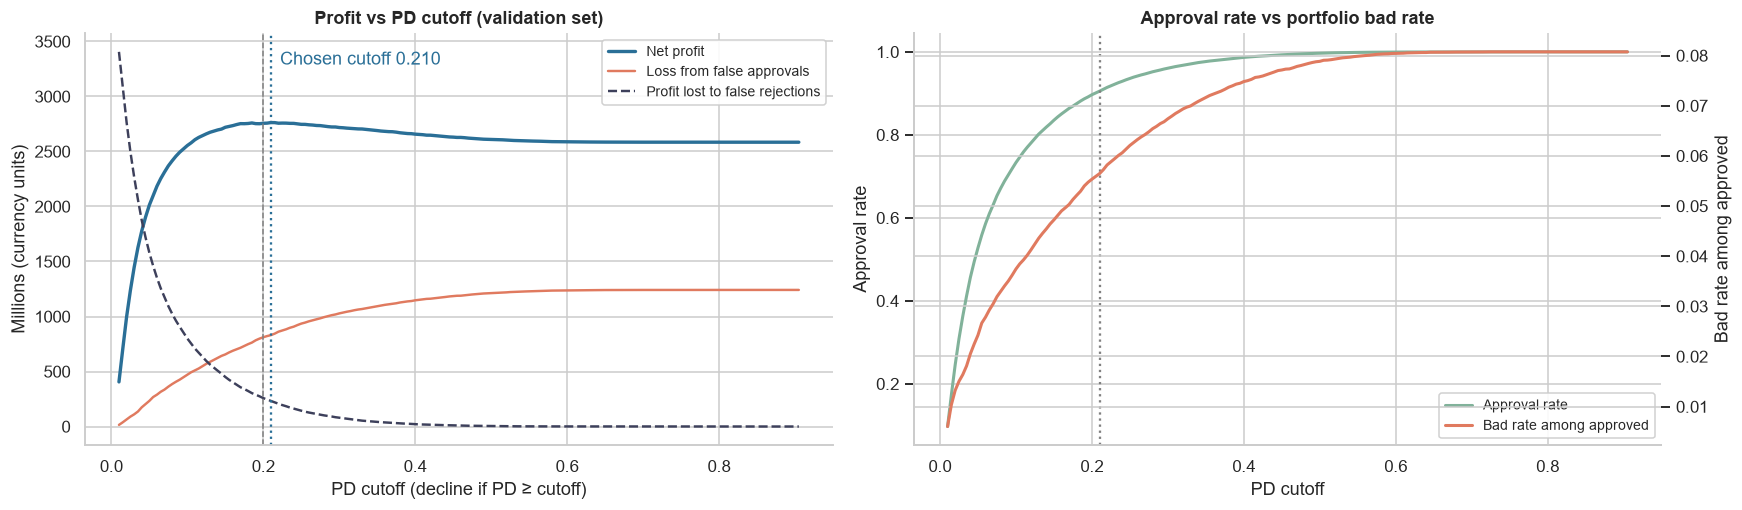

In [4]:
best_t = float(cands.loc["Max net profit (empirical)", "threshold"])
fig, axes = plt.subplots(1, 2, figsize=(16, 4.8))
plot_profit_curve(sweep, best_t, break_even_pd(LGD, MARGIN), ax=axes[0])
plot_tradeoff(sweep, best_t, ax=axes[1])
fig.tight_layout()
savefig(fig, "threshold_profit_curve")
plt.show()

**How to read this:** moving the cutoff left (stricter) cuts losses from false approvals, but each step rejects more
good customers. Net profit peaks where the marginal applicant's expected loss equals their expected profit.
F1 and Youden ignore the 4:1 cost asymmetry (LGD 60% vs margin 15%), so they pick cutoffs that are too strict or too loose.

## 3. False approvals vs false rejections at the chosen cutoff

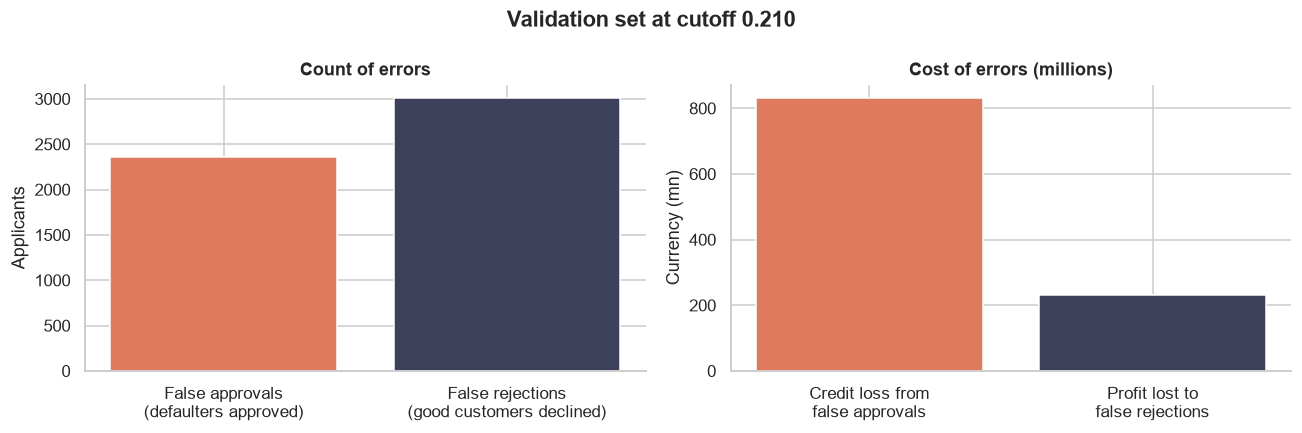

In [5]:
row = sweep.loc[sweep["net_profit"].idxmax()]
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].bar(["False approvals\n(defaulters approved)", "False rejections\n(good customers declined)"],
            [row["false_approvals"], row["false_rejections"]], color=[COLORS["bad"], COLORS["neutral"]])
axes[0].set(title="Count of errors", ylabel="Applicants")
axes[1].bar(["Credit loss from\nfalse approvals", "Profit lost to\nfalse rejections"],
            [row["loss_false_approvals"] / 1e6, row["lost_profit_false_rejections"] / 1e6], color=[COLORS["bad"], COLORS["neutral"]])
axes[1].set(title="Cost of errors (millions)", ylabel="Currency (mn)")
fig.suptitle(f"Validation set at cutoff {best_t:.3f}", fontweight="bold")
fig.tight_layout()
savefig(fig, "threshold_error_costs")
plt.show()

Notice the asymmetry: each false approval loses 60% of the loan, while each false rejection only forgoes a 15% margin.
So at the optimum the policy accepts roughly four false rejections for every false approval it avoids, and the
error *counts* look lopsided even though the policy is balanced in money terms.

## 4. Out-of-sample check on the test set
Compare the chosen policy against two naive policies the business might otherwise use.

In [6]:
y_te, ead_te = test[TARGET].to_numpy(), test["AMT_CREDIT"].to_numpy()
test_sweep = threshold_sweep(y_te, pd_test, ead_te, LGD, MARGIN, thresholds=np.array([1.01, 0.5, best_t]))
test_sweep.index = ["Approve everyone", "Model @ 0.50", f"Model @ {best_t:.3f} (profit-optimal)"]
display(test_sweep[["approval_rate", "bad_rate_approved", "false_approvals", "false_rejections",
                    "loss_false_approvals", "lost_profit_false_rejections", "net_profit", "losses_avoided_pct"]]
        .style.format({"approval_rate": "{:.1%}", "bad_rate_approved": "{:.2%}", "false_approvals": "{:,.0f}", "false_rejections": "{:,.0f}",
                       "loss_false_approvals": "{:,.0f}", "lost_profit_false_rejections": "{:,.0f}", "net_profit": "{:,.0f}", "losses_avoided_pct": "{:.1%}"}))
uplift = test_sweep["net_profit"].iloc[2] - test_sweep["net_profit"].iloc[0]
print(f"Profit uplift vs approving everyone on the test set: {uplift:,.0f} ({uplift / abs(test_sweep['net_profit'].iloc[0]):+.1%})")

,approval_rate,bad_rate_approved,false_approvals,false_rejections,loss_false_approvals,lost_profit_false_rejections,net_profit,losses_avoided_pct
Approve everyone,100.0%,8.07%,"3,724",0,"1,245,005,518",0,"2,577,742,628",0.0%
Model @ 0.50,99.6%,7.85%,"3,609",60,"1,211,343,555","4,204,584","2,607,200,008",2.7%
Model @ 0.210 (profit-optimal),90.6%,5.57%,"2,328","2,961","826,259,967","225,910,402","2,770,577,777",33.6%


Profit uplift vs approving everyone on the test set: 192,835,150 (+7.5%)


## 5. Sensitivity analysis: how the cutoff depends on the assumptions
Finance and risk will challenge the LGD and margin numbers. Show them how the optimal cutoff and approval rate move.

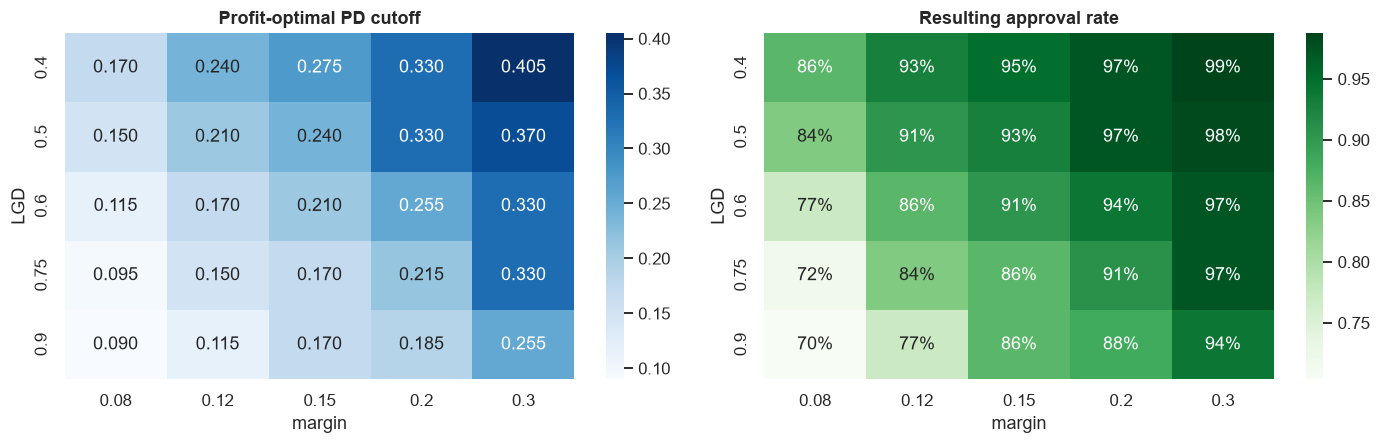

In [7]:
grid = []
for lgd in [0.40, 0.50, 0.60, 0.75, 0.90]:
    for margin in [0.08, 0.12, 0.15, 0.20, 0.30]:
        s = threshold_sweep(valid[TARGET], pd_valid, valid["AMT_CREDIT"], lgd, margin)
        b = s.loc[s["net_profit"].idxmax()]
        grid.append({"LGD": lgd, "margin": margin, "optimal_cutoff": b["threshold"], "approval_rate": b["approval_rate"],
                     "break_even_pd": break_even_pd(lgd, margin)})
grid = pd.DataFrame(grid)
fig, axes = plt.subplots(1, 2, figsize=(13, 4.2))
import seaborn as sns
sns.heatmap(grid.pivot(index="LGD", columns="margin", values="optimal_cutoff"), annot=True, fmt=".3f", cmap="Blues", ax=axes[0])
axes[0].set_title("Profit-optimal PD cutoff")
sns.heatmap(grid.pivot(index="LGD", columns="margin", values="approval_rate"), annot=True, fmt=".0%", cmap="Greens", ax=axes[1])
axes[1].set_title("Resulting approval rate")
fig.tight_layout()
savefig(fig, "threshold_sensitivity")
plt.show()

## 6. From one cutoff to a lending policy: Approve / Refer / Decline
Real lenders rarely use a single hard cutoff. Applicants just below the decline line go to an **underwriter**,
who can request documents or reduce the loan amount. We also map PDs to **risk grades** used for pricing.

In [8]:
policy = make_policy(best_t, cfg["business"]["refer_band_ratio"], LGD, MARGIN, cfg["risk_grades"])
policy["selected_on"] = "validation net profit"
save_policy(policy, paths["models"] / "decision_policy.json")

decisions = assign_decision(pd_test, policy)
grades = assign_grade(pd_test, cfg["risk_grades"])
policy_view = (pd.DataFrame({"decision": decisions, "TARGET": y_te, "pd": pd_test, "credit": ead_te})
               .groupby("decision").agg(applicants=("TARGET", "size"), actual_default_rate=("TARGET", "mean"),
                                        mean_pd=("pd", "mean"), credit_mn=("credit", lambda s: s.sum() / 1e6)))
policy_view["share"] = policy_view["applicants"] / policy_view["applicants"].sum()
display(policy_view.reindex(["Approve", "Refer to underwriter", "Decline"]).style.format(
    {"actual_default_rate": "{:.2%}", "mean_pd": "{:.2%}", "credit_mn": "{:,.1f}", "share": "{:.1%}"}))

grade_view = (pd.DataFrame({"grade": grades, "TARGET": y_te, "pd": pd_test})
              .groupby("grade").agg(applicants=("TARGET", "size"), actual_default_rate=("TARGET", "mean"), mean_pd=("pd", "mean")))
grade_view["pd_upper_bound"] = pd.Series(cfg["risk_grades"])
grade_view.style.format({"actual_default_rate": "{:.2%}", "mean_pd": "{:.2%}", "pd_upper_bound": "{:.0%}"})

,applicants,actual_default_rate,mean_pd,credit_mn,share
decision,,,,,
Approve,38374,4.59%,4.67%,"23,507.5",83.2%
Refer to underwriter,3396,16.70%,17.54%,"1,848.5",7.4%
Decline,4357,32.04%,30.72%,"2,204.0",9.4%


,applicants,actual_default_rate,mean_pd,pd_upper_bound
grade,,,,
A,16904,1.83%,1.60%,3%
B,10156,4.17%,4.35%,6%
C,6773,7.57%,7.80%,10%
D,7516,13.19%,14.11%,20%
E,4778,31.14%,29.81%,100%


In [9]:
sweep.to_csv(paths["reports"] / "threshold_sweep_validation.csv", index=False)
grid.to_csv(paths["reports"] / "threshold_sensitivity.csv", index=False)
print("Policy saved to models/decision_policy.json:")
policy

Policy saved to models/decision_policy.json:


{'decline_at_or_above': 0.21,
 'auto_approve_below': 0.147,
 'lgd': 0.6,
 'profit_margin': 0.15,
 'break_even_pd': 0.19999999999999998,
 'risk_grades': {'A': 0.03, 'B': 0.06, 'C': 0.1, 'D': 0.2, 'E': 1.0},
 'selected_on': 'validation net profit'}